# M&A の失敗を予測する：公開 CSV から EDA・モデル・検証まで

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Asmirai/edinet-ma-ledger/blob/main/notebooks/quickstart.ipynb)

このノートブックは、記事「[M&A 2,429件のデータから、失敗する買収を見抜くAIを作った](https://qiita.com/ykuchiki/items/18d31329d81581d56a61)」の分析を、公開している台帳の CSV だけでたどります。EDINET の API キーは要りません。

1. 台帳を読み、目的変数（買収から3年以内にのれんを減損したか）を確かめる
2. 探索的データ分析（EDA）：説明変数で買収を4つのグループに分け、失敗率を比べる
3. 交絡の確認：新規参入の失敗が多く見えた理由を、業種の関係で分けて確かめる
4. 予測モデル：2019年度までで学習し、2020年度以降で確かめる（時系列のホールドアウト検証）
5. スコアリング：記事の例の候補4社に、失敗の確率を付ける

図の文字は、Colab でも崩れないように英語にしています。

## 準備：リポジトリと台帳の CSV

In [1]:
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

REPO_URL = "https://github.com/Asmirai/edinet-ma-ledger.git"
CSV_URL = "https://github.com/Asmirai/edinet-ma-ledger/releases/latest/download/ma_ledger.csv"

# Colab では、リポジトリを取ってきてその中で動かす。手元では、notebooks/ の1つ上で動かす
if "google.colab" in sys.modules and not Path("edinet-ma-ledger").exists():
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
if Path("edinet-ma-ledger").exists():
    os.chdir("edinet-ma-ledger")
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

ledger_path = Path("data/public/ma_ledger.csv")
if not ledger_path.exists():
    ledger_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(CSV_URL, ledger_path)
print(ledger_path, ledger_path.stat().st_size, "bytes")

data/public/ma_ledger.csv 2195460 bytes


## 1. 台帳を読み、目的変数を確かめる

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

ledger = pd.read_csv(ledger_path, encoding="utf-8-sig")
print(f"{len(ledger):,} 行、買収 {ledger['deal_id'].nunique():,} 件")

judged = ledger[(ledger["primary"]) & ledger["goodwill_impaired"].notna()].copy()
judged = judged[judged["base_year"] <= 2022]
judged["impaired"] = judged["goodwill_impaired"].astype(bool)
print(
    f"減損を判定できた買収 {len(judged):,} 件のうち、減損した割合 {judged['impaired'].mean():.1%}"
)

6,405 行、買収 6,324 件
減損を判定できた買収 2,429 件のうち、減損した割合 15.6%


目的変数は、買収から3年以内に、その買収で生じたのれんを減損したか（`goodwill_impaired`）です。のれんは、相手の価値（純資産）を超えて上乗せして払った分で、減損は、その上乗せを損失にしたことを表します。

## 2. EDA：説明変数でグループに分け、失敗率を比べる

モデルと同じく、上乗せ率が150%を超える買収（学習した範囲の外）を除いて数えます。記事の図は除かずに数えているので、割合は少しだけ違います（異業種は記事の25.7%に対して24.5%）。

          premium (goodwill / price) acquirer equity ratio  \
Q1 (low)                        7.9%                 10.4%   
Q2                             15.4%                 14.7%   
Q3                             15.6%                 16.4%   
Q4 (high)                      21.8%                 20.5%   

          deal size / acquirer assets  
Q1 (low)                        10.7%  
Q2                              15.1%  
Q3                              16.2%  
Q4 (high)                       18.8%  


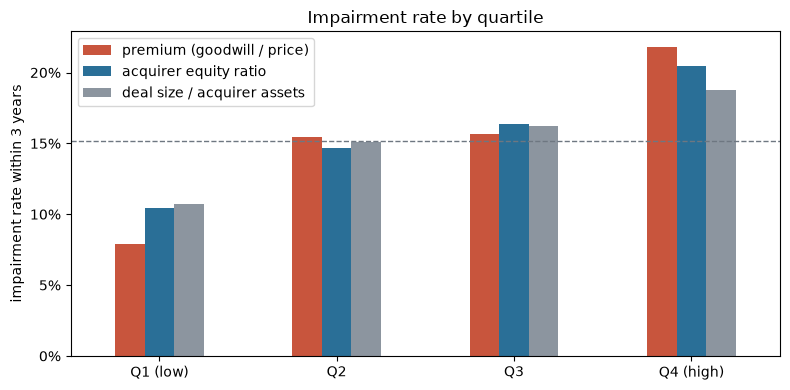

In [3]:
judged["goodwill_ratio"] = judged["goodwill_yen"] / judged["consideration_yen"]
judged = judged[(judged["goodwill_ratio"] >= 0) & (judged["goodwill_ratio"] <= 1.5)]


def rate_by_quartile(column: str) -> pd.Series:
    groups = pd.qcut(judged[column], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
    return judged.groupby(groups, observed=True)["impaired"].mean()


rates = pd.DataFrame(
    {
        "premium (goodwill / price)": rate_by_quartile("goodwill_ratio"),
        "acquirer equity ratio": rate_by_quartile("acquirer_equity_ratio"),
        "deal size / acquirer assets": rate_by_quartile("size_ratio"),
    }
)
print(rates.map(lambda v: f"{v:.1%}"))

ax = rates.plot.bar(figsize=(8, 4), rot=0, color=["#c8553d", "#2a6f97", "#8c959f"])
ax.axhline(judged["impaired"].mean(), color="#6e7781", linestyle="--", linewidth=1)
ax.set_ylabel("impairment rate within 3 years")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Impairment rate by quartile")
plt.tight_layout()
plt.show()

In [4]:
relatedness_names = {
    "同業種": "same industry",
    "関連業種": "related",
    "異業種": "different industry",
}
by_relatedness = judged.groupby("relatedness")["impaired"].agg(["mean", "size"])
by_relatedness.index = by_relatedness.index.map(relatedness_names)
print(by_relatedness.assign(mean=by_relatedness["mean"].map(lambda v: f"{v:.1%}")))

                     mean  size
relatedness                    
same industry       13.0%   961
different industry  24.5%   147
related             16.0%   965


上乗せ率が高いほど、異業種の買収ほど、そして意外にも自己資本比率が高い（借金の少ない）会社ほど、失敗率が高くなっています。

## 3. 交絡の確認：新規参入が危なく見えた理由

In [5]:
judged["new_entry"] = judged["purpose"] == "新しい事業への参入"
print("異業種の買収が占める割合")
print(judged.groupby("new_entry")["relatedness"].apply(lambda s: f"{(s == '異業種').mean():.0%}"))
print()
print("失敗率：すべての買収と、関連業種の買収だけ")
print(
    pd.DataFrame(
        {
            "all": judged.groupby("new_entry")["impaired"].mean(),
            "related only": judged[judged["relatedness"] == "関連業種"]
            .groupby("new_entry")["impaired"]
            .mean(),
        }
    ).map(lambda v: f"{v:.1%}")
)

異業種の買収が占める割合
new_entry
False     2%
True     37%
Name: relatedness, dtype: str

失敗率：すべての買収と、関連業種の買収だけ
             all related only
new_entry                    
False      14.3%        15.8%
True       20.3%        16.8%


新規参入の買収は、異業種の買収を多く含みます。関連業種の買収だけで比べると、新規参入とそれ以外の差は小さくなります。目的そのものより、業種の関係が失敗率の差を生んでいたと読めます。

## 4. 予測モデル：2019年度までで学習し、2020年度以降で確かめる

学習 850 件、確かめ 869 件、AUC 0.687
                n   rate  mean_probability
1 (safest)    173   2.9%          0.075361
2             174  12.6%          0.102086
3             174  17.8%          0.124839
4             174  23.0%          0.151722
5 (riskiest)  174  29.9%          0.204146


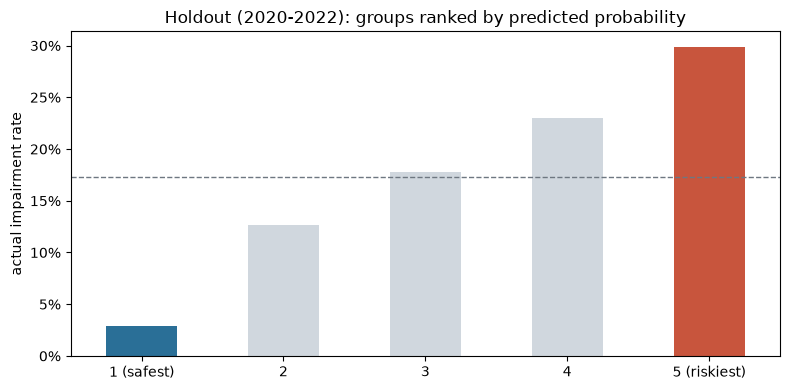

In [6]:
from ledger.scorer import holdout, read_ledger

rows = read_ledger(ledger_path)
result = holdout(rows, last_train_year=2019)
print(f"学習 {result['train_n']} 件、確かめ {result['n']} 件、AUC {result['auc']:.3f}")

groups = pd.DataFrame(result["groups"])
groups.index = ["1 (safest)", "2", "3", "4", "5 (riskiest)"]
print(groups.assign(rate=groups["rate"].map(lambda v: f"{v:.1%}")))

ax = groups["rate"].plot.bar(
    figsize=(8, 4), rot=0, color=["#2a6f97", "#d0d7de", "#d0d7de", "#d0d7de", "#c8553d"]
)
ax.axhline(result["base_rate"], color="#6e7781", linestyle="--", linewidth=1)
ax.set_ylabel("actual impairment rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Holdout (2020-2022): groups ranked by predicted probability")
plt.tight_layout()
plt.show()

モデルは、上乗せ率・買収額 ÷ 自社の総資産（対数）・自社の自己資本比率・業種の関係の4つを使うロジスティック回帰です。学習に使っていない2020年度以降の買収で、最も安全とした20%と最も危ないとした20%の失敗率に、約10倍の差がつきました。

この検証の結果は、実際より良く出ている可能性があります。4つの説明変数は、全期間のデータを見て選んでいるためです。詳しくは [モデルカード](../docs/model_card.md) にあります。

## 5. スコアリング：候補に失敗の確率を付ける

In [7]:
from ledger.scorer import fit_scorer, rank_candidates, read_candidates

candidates = read_candidates(Path("examples/candidates.csv"))
for name, probability in rank_candidates(fit_scorer(rows), candidates):
    print(f"{name}\t{probability:.1%}")

B社	9.0%
C社	18.3%
E社	20.7%
D社	34.2%


自分の候補で試すときは、`examples/candidates.csv` と同じ列の CSV を作って `read_candidates` に渡してください。ブラウザで試せる[シミュレーター](https://asmirai.github.io/edinet-ma-ledger/)もあります。

出典：EDINET閲覧（提出）サイト、公共データ利用規約（第1.0版）。合同会社Asmirai が、有価証券報告書から AI を使って買収の記載を抜き出し、加工したものです。国が作成した情報そのものではありません。